<a href="https://colab.research.google.com/github/naifahamanda/Studi_Kasus_Informatics_Practitioner_Lecture_Series_2026/blob/main/studi_kasus_dan_implementasi_materi_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Studi Kasus: Sistem Prediksi Risiko Penyakit dan Pembentukan Klaster Profil Kesehatan Pasien**
1. Latar Belakang Masalah
Dalam dunia medis dan kesehatan, analisis data historis pasien menjadi kunci untuk membantu diagnosa awal serta pencegahan penyakit. Mengacu pada penjelasan materi webinar, Machine Learning dapat diterapkan untuk dua pendekatan utama:

Supervised Learning (Klasifikasi): Mengidentifikasi apakah seorang pasien berisiko memiliki indikasi penyakit (misalnya: Disease vs No Disease) berdasarkan parameter kesehatan historis yang berlabel (labeled data).

Unsupervised Learning (Clustering): Mengelompokkan profil pasien yang serupa (customer/patient segmentation) berdasarkan kesamaan fitur tanpa label (unlabeled data) untuk personalisasi perawatan atau analisis pola medis tersembunyi.

2. Alur Kerja ML (Machine Learning Workflow)
Data Collection & Preprocessing: Pembersihan data berantakan/hilang (handling missing values), pembuangan duplikat, dan feature scaling/normalization.

Data Splitting: Membagi data menjadi Training Set (80%) dan Testing Set (20%).

Supervised Learning Modeling: Melatih model Random Forest/Logistic Regression dan mengukur performanya menggunakan matriks evaluasi (Accuracy, Precision, Recall, F1-Score, dan Confusion Matrix).

Unsupervised Learning Modeling: Mengelompokkan pasien menggunakan algoritma K-Means Clustering berbasis jarak terdekat (distance-based).

In [ ]:
# Import library dasar dan Machine Learning
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.cluster import KMeans

# Set tampilan grafik
sns.set_theme(style="whitegrid")
print("✅ Library Machine Learning berhasil dimuat!")

✅ Library Machine Learning berhasil dimuat!


In [ ]:
np.random.seed(42)
n_samples = 500

# Simulasi data parameter kesehatan pasien
data = {
    'Age': np.random.randint(20, 75, size=n_samples),
    'Blood_Pressure': np.random.normal(120, 15, size=n_samples),
    'Glucose_Level': np.random.normal(100, 25, size=n_samples),
    'Cholesterol': np.random.normal(200, 35, size=n_samples),
    'BMI': np.random.uniform(18.5, 35.0, size=n_samples)
}

df = pd.DataFrame(data)

# Membuat target label (Supervised) berbasis aturan sintetis
# Pasien dengan Glukosa > 115 dan BP > 125 berisiko lebih tinggi terkena penyakit
risk_score = (df['Glucose_Level'] * 0.4) + (df['Blood_Pressure'] * 0.3) + (df['Age'] * 0.3)
df['Target_Disease'] = (risk_score > 90).astype(int)  # 1: Disease, 0: No Disease

# Simulasi missing values (Data Preprocessing)
df.loc[np.random.choice(df.index, 15), 'Glucose_Level'] = np.nan

print(f"✅ Dataset berhasil dibuat! Jumlah sampel: {df.shape[0]} baris, {df.shape[1]} kolom.")
df.head()

✅ Dataset berhasil dibuat! Jumlah sampel: 500 baris, 6 kolom.


,Age,Blood_Pressure,Glucose_Level,Cholesterol,BMI,Target_Disease
0,58,108.517360,74.982071,178.376556,27.289152,0
1,71,126.334706,146.349134,266.377303,28.978970,1
2,48,100.381286,127.575632,259.799123,25.922396,1
3,34,90.141007,128.785634,185.561637,22.104313,0
4,62,107.136767,103.016181,213.648621,20.484079,1


In [ ]:
# 1. Pembersihan Missing Values (Imputasi dengan Nilai Median)
df['Glucose_Level'] = df['Glucose_Level'].fillna(df['Glucose_Level'].median())

# 2. Pemisahan Fitur (X) dan Target (y)
X = df.drop(columns=['Target_Disease'])
y = df['Target_Disease']

# 3. Data Splitting (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"✅ Data Preprocessing selesai.")
print(f"   Ukuran Data Latih (Training Set): {X_train_scaled.shape[0]} sampel")
print(f"   Ukuran Data Uji (Testing Set)   : {X_test_scaled.shape[0]} sampel")

✅ Data Preprocessing selesai.
   Ukuran Data Latih (Training Set): 400 sampel
   Ukuran Data Uji (Testing Set)   : 100 sampel


📊 --- EVALUASI MODEL SUPERVISED LEARNING (KLASIFIKASI) ---
Akurasi Model: 91.00%

Laporan Klasifikasi Detail:
                precision    recall  f1-score   support

No Disease (0)       0.97      0.83      0.89        46
   Disease (1)       0.87      0.98      0.92        54

      accuracy                           0.91       100
     macro avg       0.92      0.90      0.91       100
  weighted avg       0.92      0.91      0.91       100



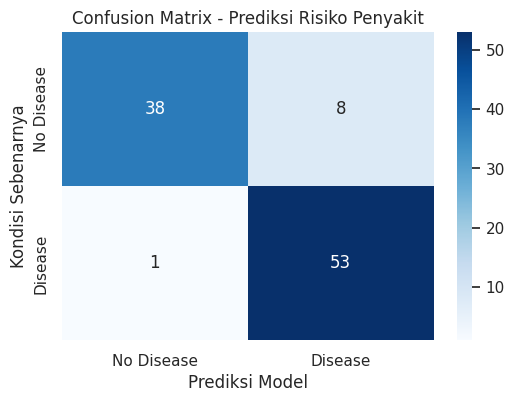

In [ ]:
# Inisialisasi dan Pelatihan Model Supervised Learning
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train_scaled, y_train)

# Prediksi pada Data Uji (Testing Set)
y_pred = clf_model.predict(X_test_scaled)

# Evaluasi Model
acc = accuracy_score(y_test, y_pred)
print("📊 --- EVALUASI MODEL SUPERVISED LEARNING (KLASIFIKASI) ---")
print(f"Akurasi Model: {acc * 100:.2f}%\n")
print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['No Disease (0)', 'Disease (1)']))

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
plt.title('Confusion Matrix - Prediksi Risiko Penyakit')
plt.xlabel('Prediksi Model')
plt.ylabel('Kondisi Sebenarnya')
plt.show()

📊 --- EVALUASI MODEL SUPERVISED LEARNING (KLASIFIKASI) ---
Akurasi Model: 91.00%

Laporan Klasifikasi Detail:
                precision    recall  f1-score   support

No Disease (0)       0.97      0.83      0.89        46
   Disease (1)       0.87      0.98      0.92        54

      accuracy                           0.91       100
     macro avg       0.92      0.90      0.91       100
  weighted avg       0.92      0.91      0.91       100



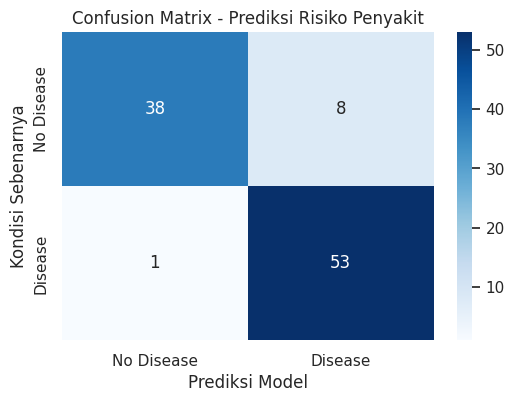

In [ ]:
# Inisialisasi dan Pelatihan Model Supervised Learning
clf_model = RandomForestClassifier(n_estimators=100, random_state=42)
clf_model.fit(X_train_scaled, y_train)

# Prediksi pada Data Uji (Testing Set)
y_pred = clf_model.predict(X_test_scaled)

# Evaluasi Model
acc = accuracy_score(y_test, y_pred)
print("📊 --- EVALUASI MODEL SUPERVISED LEARNING (KLASIFIKASI) ---")
print(f"Akurasi Model: {acc * 100:.2f}%\n")
print("Laporan Klasifikasi Detail:")
print(classification_report(y_test, y_pred, target_names=['No Disease (0)', 'Disease (1)']))

# Visualisasi Confusion Matrix
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'], yticklabels=['No Disease', 'Disease'])
plt.title('Confusion Matrix - Prediksi Risiko Penyakit')
plt.xlabel('Prediksi Model')
plt.ylabel('Kondisi Sebenarnya')
plt.show()

📊 --- HASIL UNSUPERVISED LEARNING (K-MEANS CLUSTERING) ---
Cluster
0    167
1    173
2    160
Name: count, dtype: int64


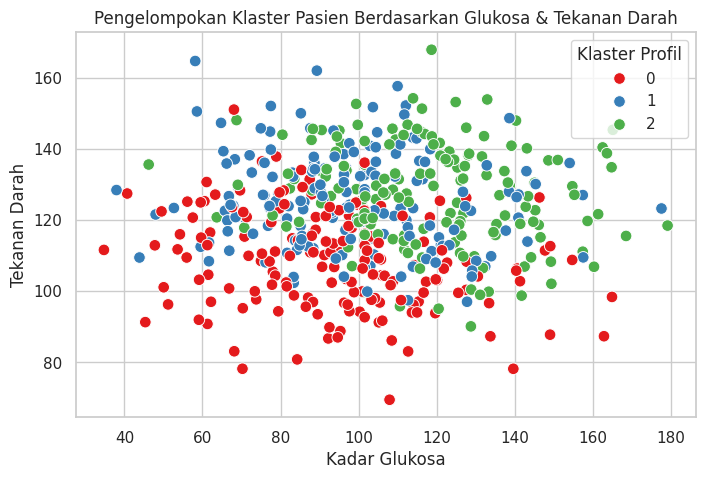

In [ ]:
# Menggunakan seluruh fitur yang telah di-scale untuk klastering Unsupervised
X_scaled_all = scaler.fit_transform(X)

# Menentukan jumlah klaster (K=3: Risiko Rendah, Sedang, Tinggi)
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled_all)

print("📊 --- HASIL UNSUPERVISED LEARNING (K-MEANS CLUSTERING) ---")
print(df['Cluster'].value_counts().sort_index())

# Visualisasi Klaster Pasien (Glukosa vs Tekanan Darah)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df, x='Glucose_Level', y='Blood_Pressure', hue='Cluster', palette='Set1', s=70
)
plt.title('Pengelompokan Klaster Pasien Berdasarkan Glukosa & Tekanan Darah')
plt.xlabel('Kadar Glukosa')
plt.ylabel('Tekanan Darah')
plt.legend(title='Klaster Profil')
plt.show()

In [ ]:
def analyze_new_patient(age, bp, glucose, cholesterol, bmi):
    # Buat DataFrame dari input
    patient_data = pd.DataFrame([[age, bp, glucose, cholesterol, bmi]], columns=X.columns)

    # Preprocessing (Scaling)
    patient_scaled = scaler.transform(patient_data)

    # Prediksi Klasifikasi (Supervised)
    disease_pred = clf_model.predict(patient_scaled)[0]
    disease_prob = clf_model.predict_proba(patient_scaled)[0][1]

    # Prediksi Klaster (Unsupervised)
    cluster_pred = kmeans.predict(patient_scaled)[0]

    # Output Hasil
    status_str = "BERISIKO PENYAKIT (Disease)" if disease_pred == 1 else "SEHAT / RISIKO RENDAH (No Disease)"

    print("🩺 --- HASIL ANALISIS KESEHATAN PASIEN BARU ---")
    print(f"Data Pasien  : Umur={age}, BP={bp}, Glukosa={glucose}, Kolesterol={cholesterol}, BMI={bmi}")
    print(f"Status Hasil : {status_str}")
    print(f"Probabilitas : {disease_prob * 100:.2f}%")
    print(f"Klaster Profil Medis: Klaster #{cluster_pred}")

# Simulasi Pengujian Pasien Baru
analyze_new_patient(age=55, bp=140, glucose=135, cholesterol=220, bmi=29.5)

🩺 --- HASIL ANALISIS KESEHATAN PASIEN BARU ---
Data Pasien  : Umur=55, BP=140, Glukosa=135, Kolesterol=220, BMI=29.5
Status Hasil : BERISIKO PENYAKIT (Disease)
Probabilitas : 100.00%
Klaster Profil Medis: Klaster #2
